# Segmentation exploratoire des clients

## Objectif metier
Peut-on reperer des groupes de clients qui ont des habitudes de commande similaires ? Des profils valides pourraient aider Panier Vert a adapter ses recommandations ou ses offres.

Cette analyse est exploratoire : elle utilise un echantillon fixe de clients, et les groupes obtenus ne sont pas des categories officielles.

## 1. Donnees et methode

Executer d'abord le notebook de nettoyage. Nous utilisons uniquement les commandes `prior`, c'est-a-dire l'historique, pour ne pas utiliser la commande cible `train` dans les caracteristiques.

Pour limiter le calcul, nous selectionnons aleatoirement 5 000 clients avec une graine fixe. Pour chacun, nous calculons des caracteristiques d'historique, de taille de panier, de reachat et d'horaires. Les variables sont mises a l'echelle avant le clustering.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

candidats = [Path.cwd(), *Path.cwd().parents]
PROJET = next((p for p in candidats if (p / "data" / "raw").is_dir()), None)
if PROJET is None:
    raise FileNotFoundError("Racine du projet introuvable : data/raw est absent.")

DONNEES = PROJET / "data" / "processed"
if not (DONNEES / "orders.csv").is_file() or not (DONNEES / "order_products__prior.csv").is_file():
    raise FileNotFoundError("Executer d'abord notebook/nettoyage_donnees.ipynb.")

TAILLE_ECHANTILLON = 5_000
TAILLE_MORCEAU = 500_000
GRAINE = 42
print(f"Projet : {PROJET}")
print(f"Echantillon vise : {TAILLE_ECHANTILLON:,} clients")

Projet : C:\Users\mouft\Desktop\data\data_m2
Echantillon vise : 5,000 clients


## 2. Tirer un echantillon reproductible de clients

On commence par lister les clients qui ont des commandes historiques `prior`. Le meme `random_state` donnera le meme echantillon a chaque execution.

In [2]:
morceaux_clients = []
for morceau in pd.read_csv(
    DONNEES / "orders.csv",
    usecols=["user_id", "eval_set"],
    chunksize=TAILLE_MORCEAU,
):
    morceaux_clients.append(
        morceau.loc[morceau["eval_set"].eq("prior"), "user_id"].unique()
    )

clients_prior = np.unique(np.concatenate(morceaux_clients))
rng = np.random.default_rng(GRAINE)
clients_echantillon = rng.choice(
    clients_prior,
    size=min(TAILLE_ECHANTILLON, len(clients_prior)),
    replace=False,
)
clients_echantillon_set = set(clients_echantillon.tolist())
print(f"Clients avec historique prior : {len(clients_prior):,}")
print(f"Clients selectionnes : {len(clients_echantillon):,}")

Clients avec historique prior : 206,209
Clients selectionnes : 5,000


## 3. Creer les caracteristiques de commandes

Pour chaque client, on mesure le nombre de commandes historiques, le delai moyen entre commandes et les horaires habituels. Les heures et jours sont representes par sinus/cosinus : ainsi 23 h et 0 h sont proches, contrairement a une moyenne arithmetique simple.

In [3]:
morceaux_commandes = []
for morceau in pd.read_csv(
    DONNEES / "orders.csv",
    usecols=["order_id", "user_id", "eval_set", "days_since_prior_order", "order_hour_of_day", "order_dow"],
    chunksize=TAILLE_MORCEAU,
):
    selection = morceau.loc[
        morceau["eval_set"].eq("prior") & morceau["user_id"].isin(clients_echantillon_set)
    ].copy()
    if not selection.empty:
        morceaux_commandes.append(selection)

commandes_clients = pd.concat(morceaux_commandes, ignore_index=True)
commandes_clients["heure_sin"] = np.sin(2 * np.pi * commandes_clients["order_hour_of_day"] / 24)
commandes_clients["heure_cos"] = np.cos(2 * np.pi * commandes_clients["order_hour_of_day"] / 24)
commandes_clients["jour_sin"] = np.sin(2 * np.pi * commandes_clients["order_dow"] / 7)
commandes_clients["jour_cos"] = np.cos(2 * np.pi * commandes_clients["order_dow"] / 7)

caracteristiques_commandes = commandes_clients.groupby("user_id").agg(
    nombre_commandes=("order_id", "nunique"),
    jours_moyens_entre_commandes=("days_since_prior_order", "mean"),
    heure_sin=("heure_sin", "mean"),
    heure_cos=("heure_cos", "mean"),
    jour_sin=("jour_sin", "mean"),
    jour_cos=("jour_cos", "mean"),
)
order_to_user = dict(zip(commandes_clients["order_id"], commandes_clients["user_id"]))
commandes_echantillon = set(order_to_user)
print(f"Commandes historiques retenues : {len(commandes_echantillon):,}")

Commandes historiques retenues : 76,256


## 4. Ajouter la taille moyenne du panier et le taux de reachat

Le fichier de produits est tres volumineux. On le lit par blocs et on ne garde que les lignes liees aux clients de l'echantillon.

In [4]:
morceaux_articles_clients = []
lignes_lues = 0
for numero_morceau, morceau in enumerate(pd.read_csv(
    DONNEES / "order_products__prior.csv",
    usecols=["order_id", "product_id", "reordered"],
    chunksize=TAILLE_MORCEAU,
)):
    lignes_lues += len(morceau)
    selection = morceau.loc[morceau["order_id"].isin(commandes_echantillon)].copy()
    if not selection.empty:
        selection["user_id"] = selection["order_id"].map(order_to_user)
        if selection["user_id"].isna().any():
            raise ValueError("Certaines commandes ne sont pas reliees a un client de l'echantillon.")
        morceaux_articles_clients.append(
            selection.groupby("user_id").agg(
                nombre_articles=("product_id", "size"),
                nombre_rachats=("reordered", "sum"),
            )
        )
    if (numero_morceau + 1) % 10 == 0:
        print(f"{lignes_lues:,} lignes lues...")

articles_clients = pd.concat(morceaux_articles_clients).groupby(level=0).sum()
caracteristiques = caracteristiques_commandes.join(articles_clients, how="inner")
if len(caracteristiques) != len(caracteristiques_commandes):
    raise ValueError("Des clients de l'echantillon n'ont pas de lignes produit associees.")
caracteristiques["taille_moyenne_panier"] = caracteristiques["nombre_articles"] / caracteristiques["nombre_commandes"]
caracteristiques["taux_reachat"] = caracteristiques["nombre_rachats"] / caracteristiques["nombre_articles"]
if caracteristiques.isna().any().any():
    raise ValueError("Des caracteristiques sont manquantes; examiner les donnees avant le clustering.")

display(caracteristiques[[
    "nombre_commandes", "jours_moyens_entre_commandes",
    "taille_moyenne_panier", "taux_reachat",
]].describe().round(2))

5,000,000 lignes lues...


10,000,000 lignes lues...


15,000,000 lignes lues...


20,000,000 lignes lues...


25,000,000 lignes lues...


30,000,000 lignes lues...


,nombre_commandes,jours_moyens_entre_commandes,taille_moyenne_panier,taux_reachat
count,5000.00,5000.00,5000.00,5000.00
mean,15.25,15.32,9.92,0.43
std,16.31,7.16,6.01,0.21
min,3.00,0.67,1.00,0.00
25%,5.00,9.55,5.60,0.27
50%,9.00,14.67,8.78,0.43
75%,19.00,20.40,13.00,0.60
max,99.00,30.00,48.60,0.95


## 5. Mettre les variables a l'echelle

Les variables n'ont pas les memes unites : jours, nombre d'articles et proportions. StandardScaler les met sur une echelle comparable. Le logarithme reduit l'effet des historiques et paniers exceptionnellement grands.

In [5]:
variables_clustering = pd.DataFrame(index=caracteristiques.index)
variables_clustering["log_commandes"] = np.log1p(caracteristiques["nombre_commandes"])
variables_clustering["jours_moyens"] = caracteristiques["jours_moyens_entre_commandes"]
variables_clustering["log_taille_panier"] = np.log1p(caracteristiques["taille_moyenne_panier"])
variables_clustering["taux_reachat"] = caracteristiques["taux_reachat"]
variables_clustering["heure_sin"] = caracteristiques["heure_sin"]
variables_clustering["heure_cos"] = caracteristiques["heure_cos"]
variables_clustering["jour_sin"] = caracteristiques["jour_sin"]
variables_clustering["jour_cos"] = caracteristiques["jour_cos"]

standardiseur = StandardScaler()
X = standardiseur.fit_transform(variables_clustering)
print(f"Matrice de clustering : {X.shape[0]:,} clients x {X.shape[1]} variables")

Matrice de clustering : 5,000 clients x 8 variables


## 6. Comparer plusieurs valeurs de K pour K-means

On compare K de 2 a 6. L'inertie aide a reperer le coude; le score de silhouette mesure si les groupes sont separes. La silhouette est estimee sur un sous-echantillon pour reduire le temps de calcul. Aucun score ne suffit seul : il faut aussi examiner les tailles et les profils des groupes.

,k,inertie,silhouette
0,2,32431.407,0.172
1,3,28867.062,0.156
2,4,26626.505,0.156
3,5,25262.902,0.151
4,6,24098.036,0.114


Meilleur score de silhouette parmi les K testes : K=2


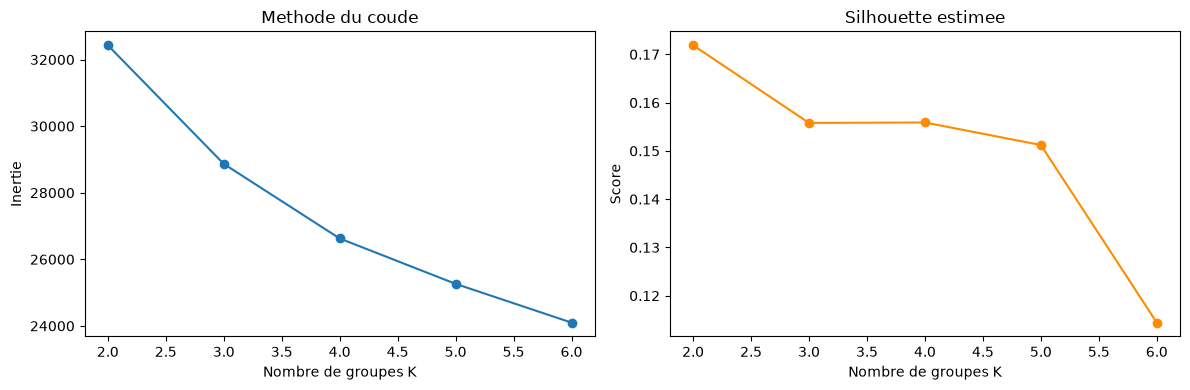

In [6]:
resultats_kmeans = []
modeles_kmeans = {}
for k in range(2, 7):
    modele = KMeans(n_clusters=k, random_state=GRAINE, n_init=10)
    etiquettes = modele.fit_predict(X)
    silhouette = silhouette_score(
        X,
        etiquettes,
        sample_size=min(1_500, len(X)),
        random_state=GRAINE,
    )
    resultats_kmeans.append({"k": k, "inertie": modele.inertia_, "silhouette": silhouette})
    modeles_kmeans[k] = etiquettes

resultats_kmeans = pd.DataFrame(resultats_kmeans)
display(resultats_kmeans.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(resultats_kmeans["k"], resultats_kmeans["inertie"], marker="o")
axes[0].set(title="Methode du coude", xlabel="Nombre de groupes K", ylabel="Inertie")
axes[1].plot(resultats_kmeans["k"], resultats_kmeans["silhouette"], marker="o", color="darkorange")
axes[1].set(title="Silhouette estimee", xlabel="Nombre de groupes K", ylabel="Score")
plt.tight_layout()
meilleur_k = int(resultats_kmeans.loc[resultats_kmeans["silhouette"].idxmax(), "k"])
print(f"Meilleur score de silhouette parmi les K testes : K={meilleur_k}")

## 7. Comparer DBSCAN

DBSCAN n'impose pas un nombre de groupes, mais depend fortement de `eps` et `min_samples`. On le teste sur le meme echantillon. Les points de bruit ont l'etiquette -1; la silhouette est calculee uniquement sur les points non-bruit lorsqu'il existe au moins deux groupes.

In [7]:
resultats_dbscan = []
for eps in [0.8, 1.0, 1.2, 1.5, 1.8]:
    etiquettes = DBSCAN(eps=eps, min_samples=15).fit_predict(X)
    groupes = sorted(set(etiquettes) - {-1})
    sans_bruit = etiquettes != -1
    score = np.nan
    if len(groupes) >= 2 and int(sans_bruit.sum()) > len(groupes):
        score = silhouette_score(
            X[sans_bruit],
            etiquettes[sans_bruit],
            sample_size=min(1_000, int(sans_bruit.sum())),
            random_state=GRAINE,
        )
    resultats_dbscan.append({
        "eps": eps,
        "nombre_groupes": len(groupes),
        "part_bruit": float((~sans_bruit).mean()),
        "silhouette_hors_bruit": score,
    })

resultats_dbscan = pd.DataFrame(resultats_dbscan)
display(resultats_dbscan.round(3))

,eps,nombre_groupes,part_bruit,silhouette_hors_bruit
0,0.8,1,0.982,NaN
1,1.0,1,0.819,NaN
2,1.2,1,0.510,NaN
3,1.5,1,0.146,NaN
4,1.8,1,0.032,NaN


## 8. Decrire les groupes K-means

On retient ici le K ayant le meilleur score parmi ceux testes, puis on decrit les groupes avec les variables d'origine. Ces profils servent a interpreter les groupes; les noms de segments devront etre choisis avec prudence.

,nombre_clients,commandes_moyennes,panier_moyen,taux_reachat_moyen,delai_moyen_jours,heure_circulaire_approx,jour_code_circulaire_approx
segment,,,,,,,
0,2866,6.32,9.38,0.30,18.92,13.90,0.44
1,2134,27.25,10.63,0.61,10.48,13.33,0.42


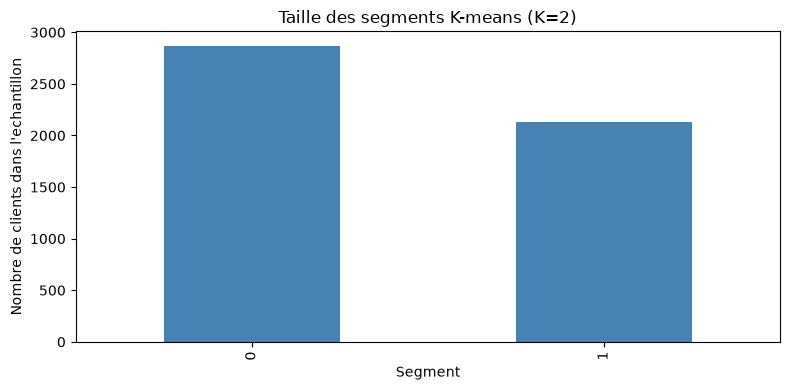

In [8]:
caracteristiques_avec_segment = caracteristiques.copy()
caracteristiques_avec_segment["segment"] = modeles_kmeans[meilleur_k]
profils_segments = caracteristiques_avec_segment.groupby("segment").agg(
    nombre_clients=("nombre_commandes", "size"),
    commandes_moyennes=("nombre_commandes", "mean"),
    panier_moyen=("taille_moyenne_panier", "mean"),
    taux_reachat_moyen=("taux_reachat", "mean"),
    delai_moyen_jours=("jours_moyens_entre_commandes", "mean"),
    heure_sin=("heure_sin", "mean"),
    heure_cos=("heure_cos", "mean"),
    jour_sin=("jour_sin", "mean"),
    jour_cos=("jour_cos", "mean"),
)
profils_segments["heure_circulaire_approx"] = (
    np.arctan2(profils_segments["heure_sin"], profils_segments["heure_cos"])
    * 24 / (2 * np.pi)
) % 24
profils_segments["jour_code_circulaire_approx"] = (
    np.arctan2(profils_segments["jour_sin"], profils_segments["jour_cos"])
    * 7 / (2 * np.pi)
) % 7
profils_segments = profils_segments.drop(columns=["heure_sin", "heure_cos", "jour_sin", "jour_cos"])
display(profils_segments.round(2))

profils_segments["nombre_clients"].plot(kind="bar", color="steelblue", figsize=(8, 4))
plt.title(f"Taille des segments K-means (K={meilleur_k})")
plt.xlabel("Segment")
plt.ylabel("Nombre de clients dans l'echantillon")
plt.tight_layout()

## 9. Conclusion et limites

Repondre a ces questions a partir du tableau :
- Les groupes ont-ils des tailles raisonnables ou un groupe domine-t-il ?
- Les groupes different-ils vraiment par la frequence, la taille du panier, les rachats ou les horaires ?
- DBSCAN trouve-t-il des groupes interpretable ou surtout du bruit ?

La segmentation porte sur 5 000 clients echantillonnes et 8 variables construites a partir de `prior`. Un score de silhouette faible ou des profils tres proches indiqueraient que ces donnees/features ne donnent pas de segments utiles. Avant d'utiliser les groupes pour des offres, il faut verifier leur stabilite sur un autre echantillon et discuter leur sens avec le metier.

## 10. Verifier la stabilite sur des clients mis de cote

Le meilleur K ci-dessus a ete choisi sur tout l'echantillon exploratoire. Pour verifier plus honnetement s'il generalise, on refait le choix de K sur 70 % des clients, puis on attribue les 30 % restants aux groupes sans les utiliser pour ajuster le modele. Une silhouette de validation proche de celle d'entrainement et des profils similaires sont de meilleurs signes de stabilite, mais ne suffisent pas seuls.

In [9]:
from sklearn.model_selection import train_test_split

indices_entrainement, indices_validation = train_test_split(
    caracteristiques.index,
    test_size=0.30,
    random_state=GRAINE + 1,
)


def preparer_variables(donnees):
    matrice = pd.DataFrame(index=donnees.index)
    matrice["log_commandes"] = np.log1p(donnees["nombre_commandes"])
    matrice["jours_moyens"] = donnees["jours_moyens_entre_commandes"]
    matrice["log_taille_panier"] = np.log1p(donnees["taille_moyenne_panier"])
    matrice["taux_reachat"] = donnees["taux_reachat"]
    for colonne in ["heure_sin", "heure_cos", "jour_sin", "jour_cos"]:
        matrice[colonne] = donnees[colonne]
    return matrice


variables_entrainement = preparer_variables(caracteristiques.loc[indices_entrainement])
variables_validation = preparer_variables(caracteristiques.loc[indices_validation])
standardiseur_validation = StandardScaler()
X_entrainement = standardiseur_validation.fit_transform(variables_entrainement)
X_validation = standardiseur_validation.transform(variables_validation)
print(f"Clients d'entrainement : {len(indices_entrainement):,}")
print(f"Clients de validation : {len(indices_validation):,}")

Clients d'entrainement : 3,500
Clients de validation : 1,500


In [10]:
scores_entrainement = []
modeles_validation = {}
for k in range(2, 7):
    modele = KMeans(n_clusters=k, random_state=GRAINE, n_init=10)
    etiquettes = modele.fit_predict(X_entrainement)
    score = silhouette_score(
        X_entrainement,
        etiquettes,
        sample_size=min(1_000, len(X_entrainement)),
        random_state=GRAINE,
    )
    scores_entrainement.append({"k": k, "silhouette_entrainement": score})
    modeles_validation[k] = modele

scores_entrainement = pd.DataFrame(scores_entrainement)
display(scores_entrainement.round(3))
k_validation = int(
    scores_entrainement.loc[
        scores_entrainement["silhouette_entrainement"].idxmax(), "k"
    ]
)
modele_validation = modeles_validation[k_validation]
etiquettes_entrainement = modele_validation.labels_
etiquettes_validation = modele_validation.predict(X_validation)
if len(np.unique(etiquettes_validation)) < 2:
    raise ValueError("Le modele n'a attribue qu'un seul groupe aux clients de validation.")
silhouette_validation = silhouette_score(
    X_validation,
    etiquettes_validation,
    sample_size=min(1_000, len(X_validation)),
    random_state=GRAINE,
)
print(f"K retenu sur l'entrainement : {k_validation}")
silhouette_entrainement = scores_entrainement.loc[
    scores_entrainement["k"].eq(k_validation), "silhouette_entrainement"
].iloc[0]
print(f"Silhouette entrainement : {silhouette_entrainement:.3f}")
print(f"Silhouette validation : {silhouette_validation:.3f}")

,k,silhouette_entrainement
0,2,0.168
1,3,0.160
2,4,0.158
3,5,0.154
4,6,0.122


K retenu sur l'entrainement : 2
Silhouette entrainement : 0.168
Silhouette validation : 0.184


In [11]:
def profiler_groupes(donnees, etiquettes):
    donnees = donnees.copy()
    donnees["segment"] = np.asarray(etiquettes)
    profils = donnees.groupby("segment").agg(
        nombre_clients=("nombre_commandes", "size"),
        commandes_moyennes=("nombre_commandes", "mean"),
        panier_moyen=("taille_moyenne_panier", "mean"),
        taux_reachat_moyen=("taux_reachat", "mean"),
        delai_moyen_jours=("jours_moyens_entre_commandes", "mean"),
    )
    profils["part_clients"] = profils["nombre_clients"] / len(donnees)
    return profils


profils_entrainement = profiler_groupes(
    caracteristiques.loc[indices_entrainement], etiquettes_entrainement
).add_suffix("_entrainement")
profils_validation = profiler_groupes(
    caracteristiques.loc[indices_validation], etiquettes_validation
).add_suffix("_validation")
comparaison_profils = profils_entrainement.join(profils_validation, how="outer")
display(comparaison_profils.round(3))

,nombre_clients_entrainement,commandes_moyennes_entrainement,panier_moyen_entrainement,taux_reachat_moyen_entrainement,delai_moyen_jours_entrainement,part_clients_entrainement,nombre_clients_validation,commandes_moyennes_validation,panier_moyen_validation,taux_reachat_moyen_validation,delai_moyen_jours_validation,part_clients_validation
segment,,,,,,,,,,,,
0,2027,6.267,9.435,0.296,18.797,0.579,833,6.397,9.304,0.298,19.174,0.555
1,1473,27.071,10.605,0.609,10.564,0.421,667,27.508,10.619,0.616,10.415,0.445


## 11. Interpretation des resultats

Les deux groupes gardent des profils proches entre l'entrainement et la validation :

- **Segment 0 - clients moins frequents (nom provisoire)** : environ 6,3 commandes historiques en moyenne, un panier moyen de 9,4 articles, un taux moyen de reachat de 0,30 et un delai moyen d'environ 19 jours. Il represente 57,9 % de l'entrainement et 55,5 % de la validation.
- **Segment 1 - clients plus frequents (nom provisoire)** : environ 27 commandes historiques en moyenne, un panier moyen de 10,6 articles, un taux moyen de reachat de 0,61 et un delai moyen d'environ 10,5 jours. Il represente 42,1 % de l'entrainement et 44,5 % de la validation.

Les tailles et les moyennes sont donc assez similaires dans les deux parties de l'echantillon. En revanche, les silhouettes de 0,168 sur l'entrainement et 0,184 sur la validation sont faibles : les clients ne sont pas nettement separes en groupes. La segmentation est **coherente dans ses profils, mais peu discriminante**.

### Conclusion a retenir

Ces groupes peuvent servir a decrire l'echantillon, mais pas encore a justifier des offres commerciales differentes. Les resultats portent sur 5 000 clients et la validation est un partage interne de cet echantillon; elle ne prouve pas que les groupes se retrouvent dans toute la clientele. Enfin, ces statistiques decrivent l'historique et ne constituent pas une prediction des prochains achats. La prochaine analyse peut donc etudier la prediction du reachat.